In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation

In [2]:
def img_process(scale=1.5): #play with this value
    img = cv2.imread("iitkgp_logo.jpg")
    img=cv2.resize(img, (300, 290))
    gray=cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (3, 3), 0) #try playing with the values
    _,thresh = cv2.threshold(blurred, 200, 255, cv2.THRESH_BINARY_INV)
    edges = cv2.Canny(thresh, 100, 200)

    pts = np.column_stack(np.where(edges > 0))

    # Convert from (row,col) to (x,y)
    pts = pts[:, [1, 0]]

    # Flip y-axis
    pts[:, 1] = img.shape[0] - pts[:, 1]


    pts = pts.astype(np.float64)
    pts -= pts.mean(axis=0)
    max_dim = np.max(np.abs(pts))
    pts = scale * pts / max_dim
    return pts

In [3]:
L1= 1.5
L2= 1.5 # play wtih these values

In [4]:
def FK(theta1,theta2):
    x1=L1*np.cos(theta1)
    y1=L1*np.sin(theta1)
    x2=x1+L2*np.cos(theta1+theta2)
    y2=y1+L2*np.sin(theta1+theta2)
    return x1, y1, x2, y2

In [5]:
def IK(x, y):
    r2 = x*x + y*y
    c2 = (r2 - L1*L1 - L2*L2)/(2*L1*L2)
    c2 = np.clip(c2, -1, 1)
    s2 = np.sqrt(1-c2*c2)
    theta2 = np.arctan2(s2, c2)
    theta1 = np.arctan2(y, x) - np.arctan2(L2*s2,L1 + L2*c2)
    return theta1, theta2

In [6]:
points = img_process()

print("Total points:", len(points))

plt.figure(figsize=(6,6))
plt.scatter(points[:,0], points[:,1], s=1)
plt.gca().set_aspect('equal')
plt.title("Extracted Logo")
plt.show()

error: OpenCV(4.13.0) D:\a\opencv-python\opencv-python\opencv\modules\imgproc\src\resize.cpp:4208: error: (-215:Assertion failed) !ssize.empty() in function 'cv::resize'


In [ ]:
def move_to(x, y, pen_down,theta1_current, theta2_current,trail, Kp, tolerance):

    theta1_target, theta2_target = IK(x, y)

    if theta1_target is None or theta2_target is None:
        print(f"Point ({x}, {y}) is unreachable.")
        return theta1_current, theta2_current, trail

    frame = 0
    while True:

        error1 = theta1_target - theta1_current
        error2 = theta2_target - theta2_current

        theta1_current += error1 * Kp
        theta2_current += error2 * Kp

        x1, y1, x2, y2 = FK(theta1_current, theta2_current)

        # Only draw when pen is down
        if pen_down:
            trail[-1].append((x2, y2))

        plt.cla()
        plt.axis("equal")
        plt.xlim(-200, 200)
        plt.ylim(-200, 200)
        # plt.grid(True)

        plt.title("2 DOF Robot Arm")
        # plt.xlabel("X")
        # plt.ylabel("Y")

        for contour_trail in trail:
            if len(contour_trail) > 1:
                plt.plot([p[0] for p in contour_trail],
                         [p[1] for p in contour_trail],
                         color="orange",
                         linewidth=2)

        plt.scatter(x, y, color="green", marker="x")

        plt.plot([0, x1], [0, y1], color="red")
        plt.plot([x1, x2], [y1, y2], color="blue")

        plt.scatter([0, x1, x2],
                    [0, y1, y2],
                    color="black")

        plt.pause(0.001)

        dist = ((x2 - x)**2 + (y2 - y)**2)**0.5
        if dist < 1:
            break

        frame += 1
        if frame > 300:
            break

    return theta1_current, theta2_current, trail

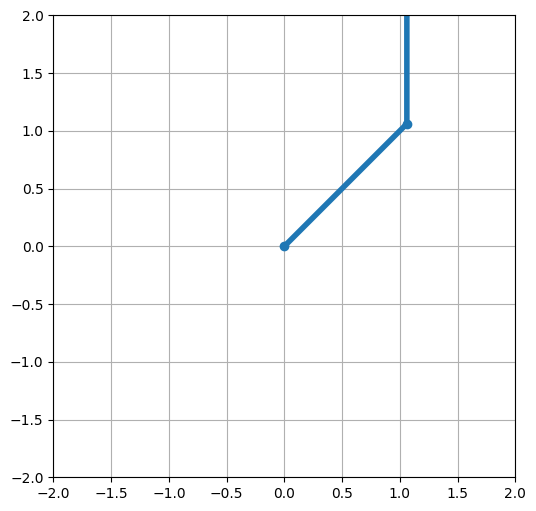

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

theta1 = np.radians(45)
theta2 = np.radians(45)

x1, y1, x2, y2 = FK(theta1, theta2)

plt.figure(figsize=(6,6))
plt.plot([0,x1,x2],[0,y1,y2],'o-',lw=4)

plt.xlim(-2,2)
plt.ylim(-2,2)
plt.gca().set_aspect('equal')
plt.grid()

plt.show()